In [ ]:
import os
import zipfile
from google.colab import drive

# 1. Google Drive connect (mount) karein
drive.mount('/content/drive')

# 2. Drive se archive.zip ko Colab mein unzip karein
zip_path = "/content/drive/MyDrive/archive.zip"

if os.path.exists(zip_path):
    print("Unzipping archive.zip....")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('/content/extracted_data')
    print("Unzip Complete!")
else:
    print("Error: archive.zip Not in MyDrive.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Unzipping archive.zip... Thora intezar karein.
Unzip Complete!


In [ ]:
import os
import shutil

# 1. Locate the dataset root containing train, val, and test
dataset_root = None
for root, dirs, files in os.walk('/content/extracted_data'):
    if 'train' in dirs and 'test' in dirs and 'val' in dirs:
        dataset_root = root
        break

if dataset_root:
    print(f"Located dataset root: {dataset_root}")

    # Save merged Packages dataset permanently in Google Drive
    output_packages_dir = "/content/drive/MyDrive/Grocery_CCP_Project/raw_grocery_data/Packages"
    metadata_dir = "/content/drive/MyDrive/Grocery_CCP_Project/dataset_metadata"

    os.makedirs(output_packages_dir, exist_ok=True)
    os.makedirs(metadata_dir, exist_ok=True)

    splits = ['train', 'val', 'test']
    total_copied = 0

    # 2. Merge ONLY the Packages folder across train, val, and test
    for split in splits:
        packages_split_path = os.path.join(dataset_root, split, "Packages")
        if not os.path.exists(packages_split_path):
            print(f"Warning: {packages_split_path} not found.")
            continue

        print(f"Merging '{split}/Packages'...")

        for root, dirs, files in os.walk(packages_split_path):
            for file in files:
                if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                    src_file = os.path.join(root, file)

                    # Preserve product type & brand/flavor hierarchy (e.g., Juice/Bravo-Apple-Juice)
                    rel_path = os.path.relpath(root, packages_split_path)
                    dest_class_dir = os.path.join(output_packages_dir, rel_path)
                    os.makedirs(dest_class_dir, exist_ok=True)

                    # Keep original filename; append _1, _2 only if filename collision occurs
                    dest_file = os.path.join(dest_class_dir, file)
                    if os.path.exists(dest_file):
                        name, ext = os.path.splitext(file)
                        counter = 1
                        while os.path.exists(os.path.join(dest_class_dir, f"{name}_{counter}{ext}")):
                            counter += 1
                        dest_file = os.path.join(dest_class_dir, f"{name}_{counter}{ext}")

                    shutil.copy2(src_file, dest_file)
                    total_copied += 1

    print(f"\nMerge Complete! Total Packages images merged: {total_copied}")
    print(f"Saved permanently at: {output_packages_dir}")

    # 3. Copy classes.csv and metadata files for reference
    for item in os.listdir(dataset_root):
        if item not in splits:
            src_item = os.path.join(dataset_root, item)
            dst_item = os.path.join(metadata_dir, item)
            if os.path.isdir(src_item):
                shutil.copytree(src_item, dst_item, dirs_exist_ok=True)
            else:
                shutil.copy2(src_item, dst_item)
    print(f"Metadata saved at: {metadata_dir}")
else:
    print("Error: Could not locate train/val/test directories inside /content/extracted_data.")

Located dataset root: /content/extracted_data/GroceryStoreDataset/dataset
Merging 'train/Packages'...
Merging 'val/Packages'...
Merging 'test/Packages'...

Merge Complete! Total Packages images merged: 1745
Saved permanently at: /content/drive/MyDrive/Grocery_CCP_Project/raw_grocery_data/Packages
Metadata saved at: /content/drive/MyDrive/Grocery_CCP_Project/dataset_metadata


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**DATA INSPECTION:-**

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image

# Define path to your merged Packages dataset on Google Drive
packages_dir = "/content/drive/MyDrive/Grocery_CCP_Project/raw_grocery_data/Packages"

if os.path.exists(packages_dir):
    print("Packages directory found successfully!\n" + "="*50)

    total_images = 0
    class_counts = {}

    # Walk through the product categories and brand/flavor folders
    for category in os.listdir(packages_dir):
        cat_path = os.path.join(packages_dir, category)
        if os.path.isdir(cat_path):
            print(f"\n[Category]: {category}")
            for subfolder in os.listdir(cat_path):
                sub_path = os.path.join(cat_path, subfolder)
                if os.path.isdir(sub_path):
                    images = [f for f in os.listdir(sub_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
                    count = len(images)
                    total_images += count
                    class_counts[f"{category}/{subfolder}"] = count
                    print(f"   └── {subfolder}: {count} images")

    print("\n" + "="*50)
    print(f"Total Fine-Grained Classes / Subfolders: {len(class_counts)}")
    print(f"Total Images Across All Packages: {total_images}")
else:
    print(f"Error: Directory not found at {packages_dir}. Please check your Google Drive path.")

Packages directory found successfully!

[Category]: Sour-Cream
   └── Arla-Sour-Cream: 42 images
   └── Arla-Ecological-Sour-Cream: 52 images

[Category]: Yoghurt
   └── Arla-Natural-Yoghurt: 83 images
   └── Arla-Mild-Vanilla-Yoghurt: 61 images
   └── Valio-Vanilla-Yoghurt: 68 images
   └── Yoggi-Vanilla-Yoghurt: 43 images
   └── Arla-Natural-Mild-Low-Fat-Yoghurt: 49 images
   └── Yoggi-Strawberry-Yoghurt: 69 images
   └── Dayfresh-Strawberry-Yougurt: 12 images

[Category]: Soyghurt
   └── Alpro-Vanilla-Soyghurt: 47 images
   └── Alpro-Blueberry-Soyghurt: 61 images

[Category]: Oat-Milk
   └── Oatly-Oat-Milk: 68 images

[Category]: Juice
   └── Bravo-Apple-Juice: 52 images
   └── Tropicana-Juice-Smooth: 50 images
   └── God-Morgon-Orange-Red-Grapefruit-Juice: 45 images
   └── Bravo-Orange-Juice: 68 images
   └── Tropicana-Mandarin-Morning: 40 images
   └── God-Morgon-Red-Grapefruit-Juice: 44 images
   └── God-Morgon-Apple-Juice: 43 images
   └── Tropicana-Golden-Grapefruit: 44 images


Displaying 4 random sample images from the dataset:


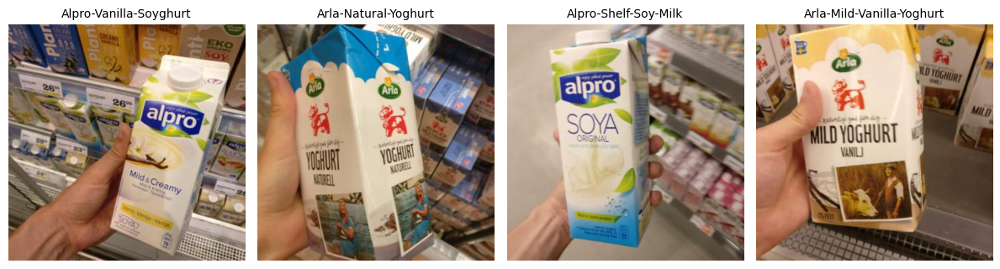

In [ ]:
import random

# Grab all valid image paths across the dataset
all_image_paths = []
for root, dirs, files in os.walk(packages_dir):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            all_image_paths.append(os.path.join(root, file))

if all_image_paths:
    print(f"Displaying 4 random sample images from the dataset:")
    plt.figure(figsize=(12, 4))
    for i in range(min(4, len(all_image_paths))):
        rand_path = random.choice(all_image_paths)
        img = Image.open(rand_path)

        plt.subplot(1, 4, i + 1)
        plt.imshow(img)
        # Extract class name from path for the title
        rel_path = os.path.relpath(rand_path, packages_dir)
        plt.title(rel_path.split('/')[1], fontsize=10)
        plt.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("No images found to display.")

**CORRUPTED IMAGES:-**

In [ ]:
import os
from PIL import Image

# Path to your packages dataset directory
packages_dir = "/content/drive/MyDrive/Grocery_CCP_Project/raw_grocery_data/Packages"

corrupted_files = []
total_checked = 0

print("Scanning for corrupted or unreadable images...")
for root, dirs, files in os.walk(packages_dir):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg', '.webp')):
            file_path = os.path.join(root, file)
            total_checked += 1
            try:
                # Verify image integrity
                with Image.open(file_path) as img:
                    img.verify()
            except Exception as e:
                corrupted_files.append(file_path)

print(f"\n[Result] Total images checked: {total_checked}")
print(f"[Result] Corrupted images found: {len(corrupted_files)}")

# Delete corrupted files if any exist
if corrupted_files:
    for bad_file in corrupted_files:
        if os.path.exists(bad_file):
            os.remove(bad_file)
            print(f"Deleted corrupted file: {bad_file}")
else:
    print("Great! All images are healthy and uncorrupted.")

Scanning for corrupted or unreadable images...

[Result] Total images checked: 2109
[Result] Corrupted images found: 0
Great! All images are healthy and uncorrupted.


**CHECK DUPLIACTE IMAGES:-**

In [ ]:
import os
import hashlib

# Path to your packages dataset directory
packages_dir = "/content/drive/MyDrive/Grocery_CCP_Project/raw_grocery_data/Packages"

hashes = {}
duplicates = []

print("Scanning for exact duplicate images...")
for root, dirs, files in os.walk(packages_dir):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg', '.webp')):
            file_path = os.path.join(root, file)
            with open(file_path, 'rb') as f:
                file_hash = hashlib.md5(f.read()).hexdigest()

            if file_hash in hashes:
                duplicates.append((file_path, hashes[file_hash]))
            else:
                hashes[file_hash] = file_path

print(f"\n[Result] Total unique images: {len(hashes)}")
print(f"[Result] Exact duplicate images found: {len(duplicates)}")



Scanning for exact duplicate images...

[Result] Total unique images: 2108
[Result] Exact duplicate images found: 1


**DELETE DUPLICATES:-**

In [ ]:
for dup_path, orig_path in duplicates:
    os.remove(dup_path)
    print(f"Deleted duplicate: {dup_path}")

Deleted duplicate: /content/drive/MyDrive/Grocery_CCP_Project/raw_grocery_data/Packages/Powder-Milk/BornVita-5star-magic/IMG_20220318_181842.jpg


In [ ]:
import os
deleted_path = "/content/drive/MyDrive/Grocery_CCP_Project/raw_grocery_data/Packages/Powder-Milk/BornVita-5star-magic/IMG_20220318_181842.jpg"
print("File exists?" , os.path.exists(deleted_path))

File exists? False


**RGB CONVERSION:-**

In [ ]:
import os
from PIL import Image

# Path to your packages dataset directory
packages_dir = "/content/drive/MyDrive/Grocery_CCP_Project/raw_grocery_data/Packages"

converted_count = 0
total_checked = 0

print("Checking color channels and converting non-RGB images to standard RGB...")
for root, dirs, files in os.walk(packages_dir):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg', '.webp')):
            file_path = os.path.join(root, file)
            total_checked += 1
            try:
                with Image.open(file_path) as img:
                    # Convert Grayscale ('L') or RGBA/Palette images to RGB
                    if img.mode != 'RGB':
                        rgb_img = img.convert('RGB')
                        rgb_img.save(file_path) # Overwrite with clean RGB version
                        converted_count += 1
            except Exception as e:
                print(f"Error processing {file_path}: {e}")

print(f"\n[Result] Total images checked: {total_checked}")
print(f"[Result] Non-RGB images converted to standard RGB: {converted_count}")

Checking color channels and converting non-RGB images to standard RGB...

[Result] Total images checked: 2108
[Result] Non-RGB images converted to standard RGB: 0


**IMAGE DIMENSION ANALYSIS:-**

In [ ]:
import os
import numpy as np
from PIL import Image

# Path to your packages dataset directory
packages_dir = "/content/drive/MyDrive/Grocery_CCP_Project/raw_grocery_data/Packages"

widths = []
heights = []

print("Analyzing image dimensions across the dataset...")
for root, dirs, files in os.walk(packages_dir):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg', '.webp')):
            file_path = os.path.join(root, file)
            try:
                with Image.open(file_path) as img:
                    w, h = img.size
                    widths.append(w)
                    heights.append(h)
            except Exception as e:
                pass

if widths and heights:
    print(f"\n--- Image Dimension Summary ---")
    print(f"Total valid images analyzed: {len(widths)}")
    print(f"Min Width: {min(widths)}px  | Max Width: {max(widths)}px  | Average Width: {int(np.mean(widths))}px")
    print(f"Min Height: {min(heights)}px | Max Height: {max(heights)}px | Average Height: {int(np.mean(heights))}px")
    print("\nRecommendation: Standardize all images to 224x224 during pipeline dataset loading.")
else:
    print("No valid images found for dimension analysis.")

Analyzing image dimensions across the dataset...

--- Image Dimension Summary ---
Total valid images analyzed: 2108
Min Width: 348px  | Max Width: 4000px  | Average Width: 643px
Min Height: 348px | Max Height: 3000px | Average Height: 637px

Recommendation: Standardize all images to 224x224 during pipeline dataset loading.


**EXPLORATORY DATA ANALYSIS:-**

**CATEGORY LEVEL DISTRIBUTION:-**

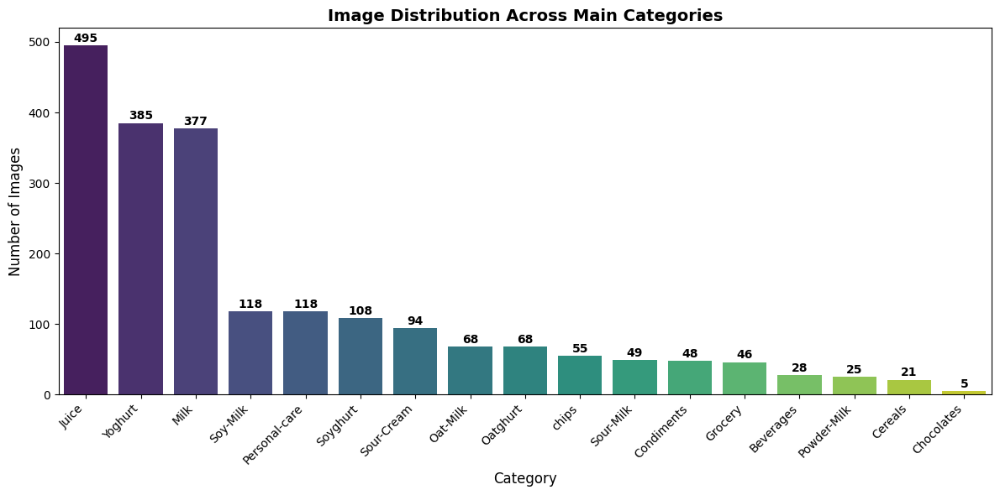

In [ ]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

packages_dir = "/content/drive/MyDrive/Grocery_CCP_Project/raw_grocery_data/Packages"

category_counts = {}
for category in os.listdir(packages_dir):
    cat_path = os.path.join(packages_dir, category)
    if os.path.isdir(cat_path):
        total_imgs = 0
        for root, _, files in os.walk(cat_path):
            total_imgs += sum(1 for f in files if f.lower().endswith(('.png', '.jpg', '.jpeg', '.webp')))
        category_counts[category] = total_imgs

sorted_cats = dict(sorted(category_counts.items(), key=lambda x: x[1], reverse=True))

plt.figure(figsize=(12, 6))
sns.barplot(x=list(sorted_cats.keys()), y=list(sorted_cats.values()), hue=list(sorted_cats.keys()), palette="viridis", legend=False)
plt.title("Image Distribution Across Main Categories", fontsize=14, fontweight="bold")
plt.xlabel("Category", fontsize=12)
plt.ylabel("Number of Images", fontsize=12)
plt.xticks(rotation=45, ha="right")
for idx, val in enumerate(sorted_cats.values()):
    plt.text(idx, val + 5, str(val), ha="center", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

**Fine-Grained Class Imbalance Check**

Total Fine-Grained Classes: 69

Top 5 Classes:
 Category                             Class  Count
 Yoghurt              Arla-Natural-Yoghurt     83
    Milk Garant-Ecological-Medium-Fat-Milk     76
    Milk              Arla-Medium-Fat-Milk     72
 Yoghurt          Yoggi-Strawberry-Yoghurt     69
 Yoghurt             Valio-Vanilla-Yoghurt     68

Bottom 5 Classes:
   Category                   Class  Count
 Beverages                Red-bull      5
Chocolates          ferrero rocher      5
 Beverages            Mountain-dew      5
 Beverages Red-bull-yellow edition      5
Condiments          Marhaba-Quince      4


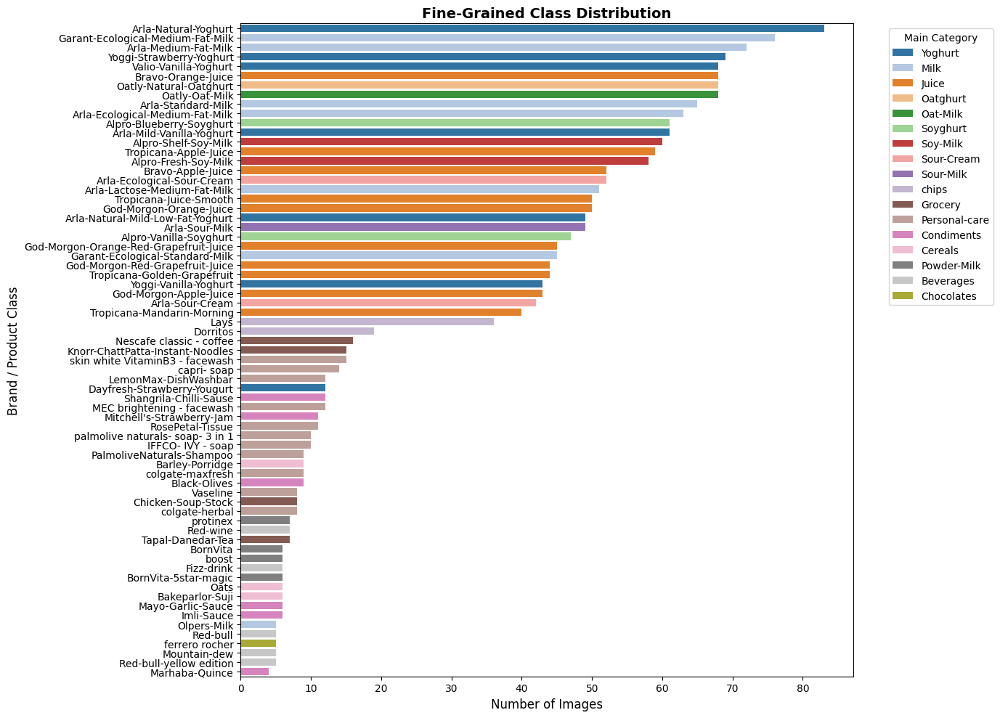

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

packages_dir = "/content/drive/MyDrive/Grocery_CCP_Project/raw_grocery_data/Packages"

class_data = []
for category in os.listdir(packages_dir):
    cat_path = os.path.join(packages_dir, category)
    if os.path.isdir(cat_path):
        for sub_class in os.listdir(cat_path):
            sub_path = os.path.join(cat_path, sub_class)
            if os.path.isdir(sub_path):
                count = sum(1 for f in os.listdir(sub_path) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.webp')))
                class_data.append({"Category": category, "Class": sub_class, "Count": count})

df_classes = pd.DataFrame(class_data).sort_values(by="Count", ascending=False)
print(f"Total Fine-Grained Classes: {len(df_classes)}")
print("\nTop 5 Classes:\n", df_classes.head(5).to_string(index=False))
print("\nBottom 5 Classes:\n", df_classes.tail(5).to_string(index=False))

plt.figure(figsize=(14, 10))
sns.barplot(data=df_classes, y="Class", x="Count", hue="Category", dodge=False, palette="tab20")
plt.title("Fine-Grained Class Distribution", fontsize=14, fontweight="bold")
plt.xlabel("Number of Images", fontsize=12)
plt.ylabel("Brand / Product Class", fontsize=12)
plt.legend(title="Main Category", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Image Aspect Ratio & Resolution Distribution**

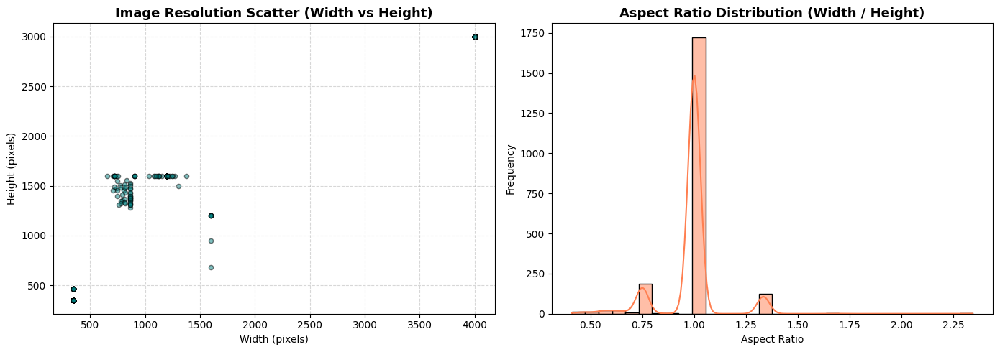

In [ ]:
import os
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

packages_dir = "/content/drive/MyDrive/Grocery_CCP_Project/raw_grocery_data/Packages"

widths, heights, aspect_ratios = [], [], []
for root, _, files in os.walk(packages_dir):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg', '.webp')):
            with Image.open(os.path.join(root, file)) as img:
                w, h = img.size
                widths.append(w)
                heights.append(h)
                aspect_ratios.append(w / h)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(widths, heights, alpha=0.5, color="teal", edgecolors="k", s=20)
axes[0].set_title("Image Resolution Scatter (Width vs Height)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Width (pixels)")
axes[0].set_ylabel("Height (pixels)")
axes[0].grid(True, linestyle="--", alpha=0.5)

sns.histplot(aspect_ratios, bins=30, kde=True, color="coral", ax=axes[1])
axes[1].set_title("Aspect Ratio Distribution (Width / Height)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Aspect Ratio")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

**Sample Grid Visualization Per Category**

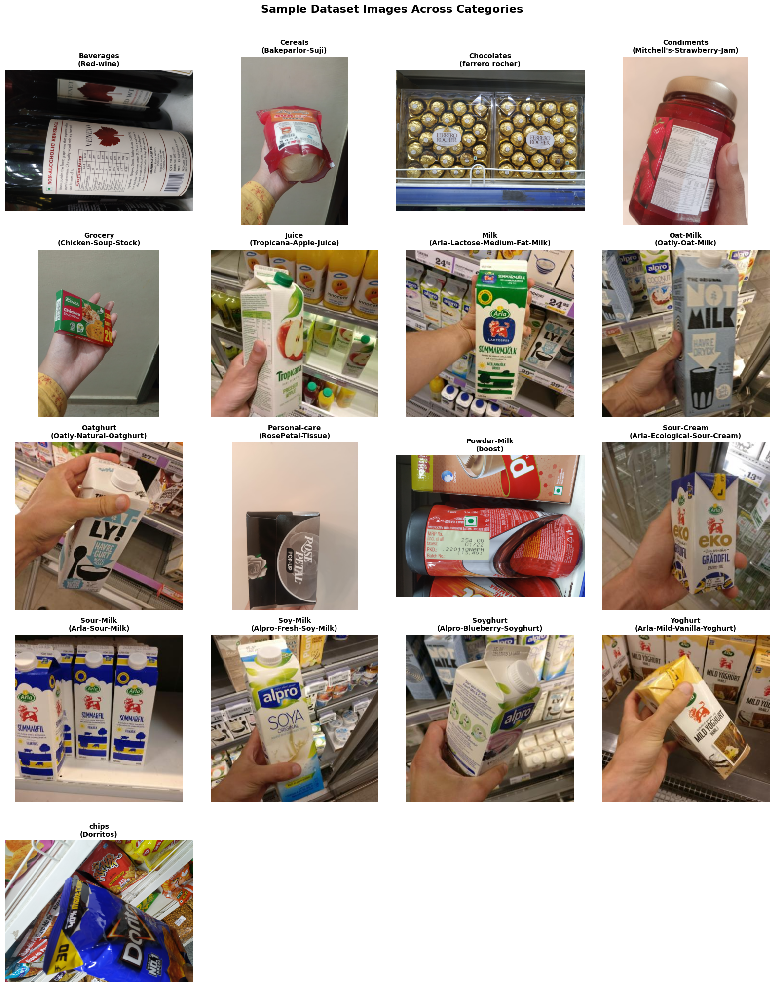

In [ ]:
import os
import random
from PIL import Image
import matplotlib.pyplot as plt

packages_dir = "/content/drive/MyDrive/Grocery_CCP_Project/raw_grocery_data/Packages"

categories = [d for d in sorted(os.listdir(packages_dir)) if os.path.isdir(os.path.join(packages_dir, d))]
num_cats = len(categories)
cols = 4
rows = (num_cats + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))
axes = axes.flatten()

for idx, category in enumerate(categories):
    cat_path = os.path.join(packages_dir, category)
    all_imgs = []
    for root, _, files in os.walk(cat_path):
        for f in files:
            if f.lower().endswith(('.png', '.jpg', '.jpeg', '.webp')):
                all_imgs.append(os.path.join(root, f))

    if all_imgs:
        sample_path = random.choice(all_imgs)
        img = Image.open(sample_path)
        axes[idx].imshow(img)
        axes[idx].set_title(f"{category}\n({os.path.basename(os.path.dirname(sample_path))})", fontsize=10, fontweight="bold")
    axes[idx].axis("off")

for idx in range(num_cats, len(axes)):
    axes[idx].axis("off")

plt.suptitle("Sample Dataset Images Across Categories", fontsize=16, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

**Brightness Analysis & Blur Detection**

Average Image Brightness (0-255): 119.04
Potentially Blurry Images (Laplacian Variance < 50): 238


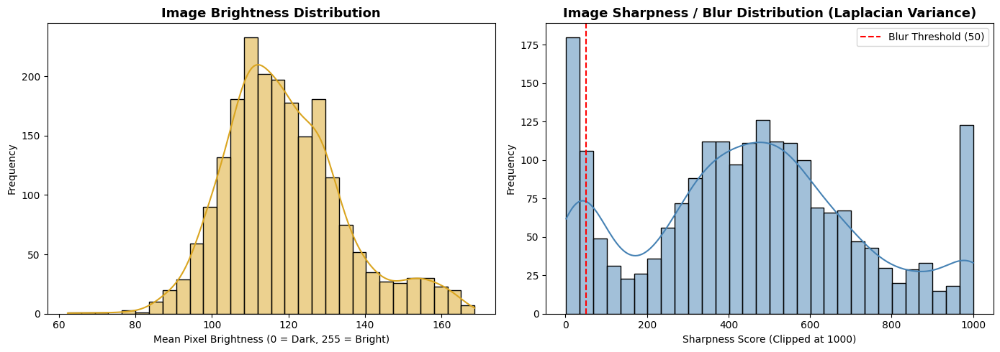

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

packages_dir = "/content/drive/MyDrive/Grocery_CCP_Project/raw_grocery_data/Packages"

brightness_vals = []
blur_scores = []
blurry_images = []

for root, _, files in os.walk(packages_dir):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg', '.webp')):
            img_path = os.path.join(root, file)
            img = cv2.imread(img_path)
            if img is not None:
                gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
                brightness = np.mean(gray)
                laplacian_var = cv2.Laplacian(gray, cv2.CV_64F).var()

                brightness_vals.append(brightness)
                blur_scores.append(laplacian_var)
                if laplacian_var < 50:
                    blurry_images.append((img_path, laplacian_var))

print(f"Average Image Brightness (0-255): {np.mean(brightness_vals):.2f}")
print(f"Potentially Blurry Images (Laplacian Variance < 50): {len(blurry_images)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(brightness_vals, bins=30, kde=True, color="goldenrod", ax=axes[0])
axes[0].set_title("Image Brightness Distribution", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Mean Pixel Brightness (0 = Dark, 255 = Bright)")
axes[0].set_ylabel("Frequency")

sns.histplot(np.clip(blur_scores, 0, 1000), bins=30, kde=True, color="steelblue", ax=axes[1])
axes[1].axvline(50, color="red", linestyle="--", label="Blur Threshold (50)")
axes[1].set_title("Image Sharpness / Blur Distribution (Laplacian Variance)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Sharpness Score (Clipped at 1000)")
axes[1].set_ylabel("Frequency")
axes[1].legend()

plt.tight_layout()
plt.show()

**CLASSIFICATION :-**

**Label Mapping & Stratified Data Splitting**

In [ ]:
import os
import pandas as pd
import numpy as np

packages_dir = "/content/drive/MyDrive/Grocery_CCP_Project/raw_grocery_data/Packages"

records = []
for category in sorted(os.listdir(packages_dir)):
    cat_path = os.path.join(packages_dir, category)
    if os.path.isdir(cat_path):
        for sub_class in sorted(os.listdir(cat_path)):
            sub_path = os.path.join(cat_path, sub_class)
            if os.path.isdir(sub_path):
                for file in os.listdir(sub_path):
                    if file.lower().endswith(('.png', '.jpg', '.jpeg', '.webp')):
                        records.append({
                            "filepath": os.path.join(sub_path, file),
                            "category": category,
                            "label_name": sub_class
                        })

df = pd.DataFrame(records)

class_names = sorted(df["label_name"].unique())
class_to_idx = {name: idx for idx, name in enumerate(class_names)}
idx_to_class = {idx: name for name, idx in class_to_idx.items()}
df["label_idx"] = df["label_name"].map(class_to_idx)

train_list, val_list, test_list = [], [], []

for label_idx, group in df.groupby("label_idx"):
    group = group.sample(frac=1, random_state=42).reset_index(drop=True)
    n = len(group)

    if n >= 7:
        n_val = max(1, int(round(n * 0.15)))
        n_test = max(1, int(round(n * 0.15)))
    elif n >= 3:
        n_val = 1
        n_test = 1
    else:
        n_val = 0
        n_test = 0

    val_list.append(group.iloc[:n_val])
    test_list.append(group.iloc[n_val:n_val + n_test])
    train_list.append(group.iloc[n_val + n_test:])

train_df = pd.concat(train_list).reset_index(drop=True)
val_df = pd.concat(val_list).reset_index(drop=True)
test_df = pd.concat(test_list).reset_index(drop=True)

print(f"Total Dataset Images : {len(df)}")
print(f"Total Classes        : {len(class_names)}")
print(f"Train Set            : {len(train_df)} images")
print(f"Validation Set       : {len(val_df)} images")
print(f"Test Set             : {len(test_df)} images")

small_classes = df["label_name"].value_counts()
print("\nClasses with < 7 images:")
print(small_classes[small_classes < 7])

Total Dataset Images : 2108
Total Classes        : 69
Train Set            : 1474 images
Validation Set       : 317 images
Test Set             : 317 images

Classes with < 7 images:
label_name
BornVita                   6
Fizz-drink                 6
Imli-Sauce                 6
boost                      6
Bakeparlor-Suji            6
Oats                       6
BornVita-5star-magic       6
Mayo-Garlic-Sauce          6
Mountain-dew               5
Red-bull                   5
Red-bull-yellow edition    5
ferrero rocher             5
Olpers-Milk                5
Marhaba-Quince             4
Name: count, dtype: int64


**DATA AUGMENTATION:-**

Train Dataset Ready : 1474 samples (with on-the-fly augmentation)
Val Dataset Ready   : 317 samples (clean resize + normalize)
Test Dataset Ready  : 317 samples (clean resize + normalize)
Standardized Tensor Shape : torch.Size([3, 224, 224]) | Pixel Range: [-2.12, 1.87]


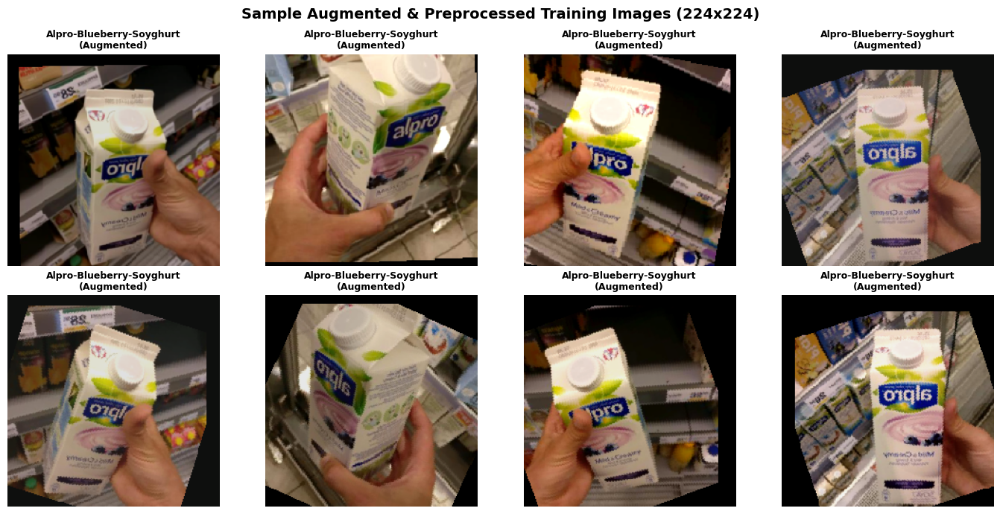

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

IMG_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=25),
    transforms.RandomAffine(degrees=0, translate=(0.08, 0.08), scale=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

val_test_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

class GroceryDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, "filepath"]
        label = int(self.df.loc[idx, "label_idx"])
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, label

train_dataset = GroceryDataset(train_df, transform=train_transforms)
val_dataset = GroceryDataset(val_df, transform=val_test_transforms)
test_dataset = GroceryDataset(test_df, transform=val_test_transforms)

print(f"Train Dataset Ready : {len(train_dataset)} samples (with on-the-fly augmentation)")
print(f"Val Dataset Ready   : {len(val_dataset)} samples (clean resize + normalize)")
print(f"Test Dataset Ready  : {len(test_dataset)} samples (clean resize + normalize)")
sample_tensor, sample_label = train_dataset[0]
print(f"Standardized Tensor Shape : {sample_tensor.shape} | Pixel Range: [{sample_tensor.min():.2f}, {sample_tensor.max():.2f}]")

def denormalize(tensor):
    img = tensor.clone().permute(1, 2, 0).numpy()
    img = img * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
    return np.clip(img, 0, 1)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()
for i in range(8):
    aug_img, lbl = train_dataset[i % 4]
    axes[i].imshow(denormalize(aug_img))
    axes[i].set_title(f"{idx_to_class[lbl]}\n(Augmented)", fontsize=9, fontweight="bold")
    axes[i].axis("off")

plt.suptitle("Sample Augmented & Preprocessed Training Images (224x224)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

MODEL TRAINING (RESNET50 AND MOBILENETV

In [ ]:
import time
import copy
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import models
from sklearn.metrics import f1_score
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training Device:", device)

BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

class_counts = train_df["label_idx"].value_counts().sort_index().values
class_weights = 1.0 / torch.tensor(class_counts, dtype=torch.float)
class_weights = (class_weights / class_weights.sum() * len(class_names)).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)

def train_model(model, model_name, num_epochs=12, lr=3e-4):
    model = model.to(device)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)

    best_model_wts = copy.deepcopy(model.state_dict())
    best_val_acc = 0.0
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    print(f"\n--- Training {model_name} ---")
    start_time = time.time()

    for epoch in range(num_epochs):
        model.train()
        running_loss, running_corrects = 0.0, 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            _, preds = torch.max(outputs, 1)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

        train_loss = running_loss / len(train_dataset)
        train_acc = running_corrects.double().item() / len(train_dataset)

        model.eval()
        val_loss_sum, val_corrects = 0.0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                _, preds = torch.max(outputs, 1)
                val_loss_sum += loss.item() * inputs.size(0)
                val_corrects += torch.sum(preds == labels.data)

        val_loss = val_loss_sum / len(val_dataset)
        val_acc = val_corrects.double().item() / len(val_dataset)
        scheduler.step(val_acc)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"Epoch {epoch+1:02d}/{num_epochs:02d} | Train Loss: {train_loss:.4f} Acc: {train_acc*100:.2f}% | Val Loss: {val_loss:.4f} Acc: {val_acc*100:.2f}%")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model_wts = copy.deepcopy(model.state_dict())

    elapsed = time.time() - start_time
    print(f"{model_name} Complete in {elapsed:.1f}s | Best Val Acc: {best_val_acc*100:.2f}%")
    model.load_state_dict(best_model_wts)
    return model, history

resnet50 = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
resnet50.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(resnet50.fc.in_features, len(class_names))
)

resnet50_trained, resnet_history = train_model(resnet50, "ResNet50", num_epochs=12, lr=3e-4)
torch.save(resnet50_trained.state_dict(), "/content/drive/MyDrive/Grocery_CCP_Project/resnet50_grocery.pth")

Training Device: cpu


In [ ]:
mobilenet_v3 = models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.IMAGENET1K_V2)
in_features = mobilenet_v3.classifier[3].in_features
mobilenet_v3.classifier[3] = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(in_features, len(class_names))
)

mobilenet_trained, mobilenet_history = train_model(mobilenet_v3, "MobileNetV3-Large", num_epochs=12, lr=3e-4)
torch.save(mobilenet_trained.state_dict(), "/content/drive/MyDrive/Grocery_CCP_Project/mobilenet_v3_grocery.pth")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 123MB/s] 



--- Training MobileNetV3-Large ---


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch 01/12 | Train Loss: 3.7365 Acc: 26.53% | Val Loss: 2.5761 Acc: 42.90%
Epoch 02/12 | Train Loss: 1.4343 Acc: 75.85% | Val Loss: 1.1216 Acc: 81.70%
Epoch 03/12 | Train Loss: 0.4459 Acc: 90.71% | Val Loss: 0.4420 Acc: 92.74%
Epoch 04/12 | Train Loss: 0.1918 Acc: 96.07% | Val Loss: 0.3315 Acc: 94.95%
Epoch 05/12 | Train Loss: 0.0887 Acc: 97.56% | Val Loss: 0.2489 Acc: 96.21%
Epoch 06/12 | Train Loss: 0.0666 Acc: 98.03% | Val Loss: 0.2178 Acc: 96.85%
Epoch 07/12 | Train Loss: 0.0853 Acc: 96.61% | Val Loss: 0.4128 Acc: 95.90%
Epoch 08/12 | Train Loss: 0.0687 Acc: 98.17% | Val Loss: 0.2560 Acc: 96.21%
Epoch 09/12 | Train Loss: 0.0712 Acc: 98.71% | Val Loss: 0.2859 Acc: 95.58%
Epoch 10/12 | Train Loss: 0.0345 Acc: 98.98% | Val Loss: 0.2228 Acc: 96.53%
Epoch 11/12 | Train Loss: 0.0299 Acc: 99.25% | Val Loss: 0.2439 Acc: 95.58%
Epoch 12/12 | Train Loss: 0.0244 Acc: 99.12% | Val Loss: 0.2002 Acc: 96.53%
MobileNetV3-Large Complete in 3023.1s | Best Val Acc: 96.85%


In [ ]:
import torch
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, classification_report

def detailed_evaluate(model, model_name, dataloader, class_names):
    model = model.to(device)
    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    f1_w = f1_score(all_labels, all_preds, average='weighted')
    f1_m = f1_score(all_labels, all_preds, average='macro')

    print(f"\n============================================================")
    print(f"                 {model_name.upper()} TEST EVALUATION REPORT")
    print(f"============================================================")
    print(f"-> Test Accuracy     : {acc * 100:.2f}%")
    print(f"-> Weighted F1-Score : {f1_w:.4f}")
    print(f"-> Macro F1-Score    : {f1_m:.4f}")
    print(f"\n--- Detailed Classification Report (Precision, Recall, F1) ---")

    # Generate classification report as a dictionary to look clean
    report = classification_report(all_labels, all_preds, target_names=class_names, output_dict=True, zero_division=0)
    report_df = pd.DataFrame(report).transpose()
    display(report_df.head(10)) # Shows metrics for top classes

    return acc, f1_w

print("Evaluating ResNet50...")
res_acc, res_f1 = detailed_evaluate(resnet50, "ResNet50", test_loader, class_names)

print("\nEvaluating MobileNetV3-Large...")
mob_acc, mob_f1 = detailed_evaluate(mobilenet_v3, "MobileNetV3-Large", test_loader, class_names)

# Final Side-by-Side Comparison Table
comparison_df = pd.DataFrame({
    "Model Architecture": ["ResNet50", "MobileNetV3-Large"],
    "Test Accuracy (%)": [f"{res_acc*100:.2f}%", f"{mob_acc*100:.2f}%"],
    "Weighted F1-Score": [f"{res_f1:.4f}", f"{mob_f1:.4f}"]
})

print("\n============================================================")
print("              FINAL MODEL PERFORMANCE COMPARISON")
print("============================================================")
display(comparison_df)

Evaluating ResNet50...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



                 RESNET50 TEST EVALUATION REPORT
-> Test Accuracy     : 96.85%
-> Weighted F1-Score : 0.9631
-> Macro F1-Score    : 0.9094

--- Detailed Classification Report (Precision, Recall, F1) ---


,precision,recall,f1-score,support
Alpro-Blueberry-Soyghurt,1.000000,1.000,1.000000,9.0
Alpro-Fresh-Soy-Milk,1.000000,1.000,1.000000,9.0
Alpro-Shelf-Soy-Milk,1.000000,1.000,1.000000,9.0
Alpro-Vanilla-Soyghurt,1.000000,1.000,1.000000,7.0
Arla-Ecological-Medium-Fat-Milk,1.000000,1.000,1.000000,9.0
Arla-Ecological-Sour-Cream,0.875000,0.875,0.875000,8.0
Arla-Lactose-Medium-Fat-Milk,1.000000,1.000,1.000000,8.0
Arla-Medium-Fat-Milk,0.916667,1.000,0.956522,11.0
Arla-Mild-Vanilla-Yoghurt,1.000000,1.000,1.000000,9.0
Arla-Natural-Mild-Low-Fat-Yoghurt,1.000000,1.000,1.000000,7.0



Evaluating MobileNetV3-Large...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



                 MOBILENETV3-LARGE TEST EVALUATION REPORT
-> Test Accuracy     : 95.27%
-> Weighted F1-Score : 0.9496
-> Macro F1-Score    : 0.8493

--- Detailed Classification Report (Precision, Recall, F1) ---


,precision,recall,f1-score,support
Alpro-Blueberry-Soyghurt,1.000,1.000000,1.000000,9.0
Alpro-Fresh-Soy-Milk,1.000,1.000000,1.000000,9.0
Alpro-Shelf-Soy-Milk,1.000,0.888889,0.941176,9.0
Alpro-Vanilla-Soyghurt,0.875,1.000000,0.933333,7.0
Arla-Ecological-Medium-Fat-Milk,1.000,1.000000,1.000000,9.0
Arla-Ecological-Sour-Cream,1.000,0.875000,0.933333,8.0
Arla-Lactose-Medium-Fat-Milk,1.000,1.000000,1.000000,8.0
Arla-Medium-Fat-Milk,1.000,1.000000,1.000000,11.0
Arla-Mild-Vanilla-Yoghurt,1.000,1.000000,1.000000,9.0
Arla-Natural-Mild-Low-Fat-Yoghurt,1.000,1.000000,1.000000,7.0



              FINAL MODEL PERFORMANCE COMPARISON


,Model Architecture,Test Accuracy (%),Weighted F1-Score
0,ResNet50,96.85%,0.9631
1,MobileNetV3-Large,95.27%,0.9496


Generating Confusion Matrix for ResNet50...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


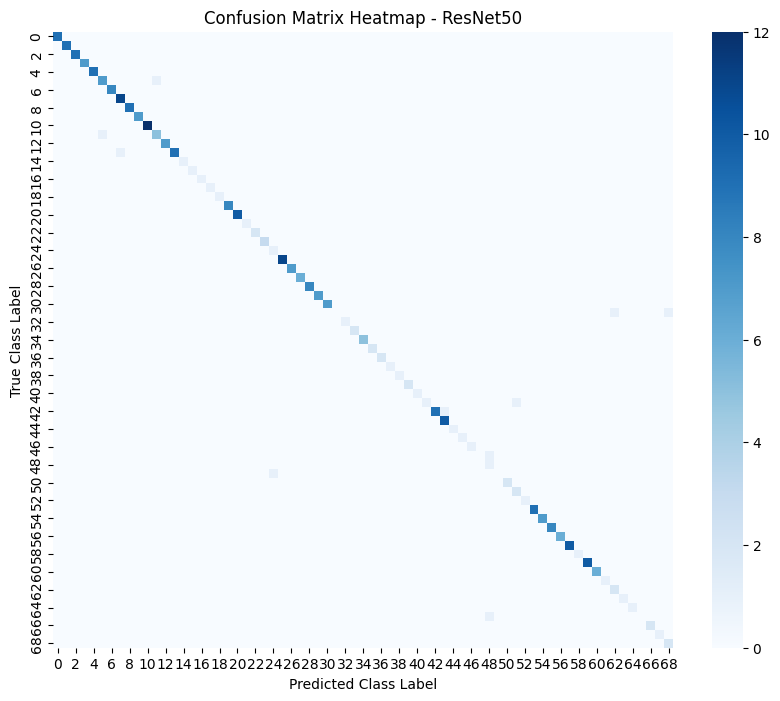

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix(model, model_name, dataloader):
    model = model.to(device)
    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    cm = confusion_matrix(all_labels, all_preds)

    # Plotting Confusion Matrix Heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=False, fmt='d', cmap='Blues', cbar=True)
    plt.title(f"Confusion Matrix Heatmap - {model_name}")
    plt.xlabel("Predicted Class Label")
    plt.ylabel("True Class Label")
    plt.show()

# ResNet50 ke liye Confusion Matrix generate karein (since yeh best performing model hai)
print("Generating Confusion Matrix for ResNet50...")
resnet50.load_state_dict(torch.load("/content/drive/MyDrive/Grocery_CCP_Project/resnet50_grocery.pth",map_location=device))
plot_confusion_matrix(resnet50, "ResNet50", test_loader)

**YOLO MODEL TRAINING, TESTING AND PERFORMANCE EVALUATION:- **

In [ ]:
import os
import shutil
from sklearn.model_selection import train_test_split

# -------------------------------------------------------------
# STEP 1: Paths Define &  Directories (Folders)
# -------------------------------------------------------------
raw_data_dir = '/content/drive/MyDrive/Grocery_CCP_Project/raw_grocery_data'
yolo_base_dir = '/content/drive/MyDrive/Grocery_CCP_Project/yolo_dataset'

# YOLO folders banana (images/train, images/val, labels/train, labels/val)
images_train_dir = os.path.join(yolo_base_dir, 'images', 'train')
images_val_dir = os.path.join(yolo_base_dir, 'images', 'val')
labels_train_dir = os.path.join(yolo_base_dir, 'labels', 'train')
labels_val_dir = os.path.join(yolo_base_dir, 'labels', 'val')

for d in [images_train_dir, images_val_dir, labels_train_dir, labels_val_dir]:
    os.makedirs(d, exist_ok=True)
print("Step 1 Done: Directories created successfully on Google Drive.")


# -------------------------------------------------------------
# STEP 2: Class Discovery (69 Classes Dhoondna)
# -------------------------------------------------------------
class_names = []
image_data_list = [] # List to store (image_path, class_id)

for root, dirs, files in os.walk(raw_data_dir):
    # Agar is folder mein koi sub-folder nahi hai, matlab yeh class folder hai
    if not dirs and files:
        class_name = os.path.basename(root)
        if class_name not in class_names:
            class_names.append(class_name)

        class_id = class_names.index(class_name)

        for file in files:
            if file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.webp')):
                img_path = os.path.join(root, file)
                image_data_list.append((img_path, class_id))

# Classes ko alphabetically sort kar lena taaki consistency rahe
class_names.sort()
image_data_list = [(img_path, class_names.index(os.path.basename(os.path.dirname(img_path)))) for img_path, _ in image_data_list]

print(f"Step 2 Done: Total Classes Found: {len(class_names)} | Total Images Found: {len(image_data_list)}")
 -------------------------------------------------------------
# STEP 3: classes.txt File Save Karna
# -------------------------------------------------------------
classes_txt_path = os.path.join(yolo_base_dir, 'classes.txt')
with open(classes_txt_path, 'w') as f:
    for c_name in class_names:
        f.write(f"{c_name}\n")
print(f"Step 3 Done: classes.txt saved at: {classes_txt_path}")


# -------------------------------------------------------------
# STEP 4: Train / Validation Split (80/20) & Saving Images/Labels
# -------------------------------------------------------------
train_imgs, val_imgs = train_test_split(image_data_list, test_size=0.2, random_state=42, stratify=[item[1] for item in image_data_list])

def process_and_save(data_subset, img_target_dir, label_target_dir):
    for img_path, c_id in data_subset:
        img_name = os.path.basename(img_path)
        parent_folder = os.path.basename(os.path.dirname(img_path))
        new_img_name = f"{parent_folder}_{img_name}"

        dest_img_path = os.path.join(img_target_dir, new_img_name)
        shutil.copy(img_path, dest_img_path)

        # YOLO format text file (.txt) banana: class_id x_center y_center width height
        # Iconic/single product images ke liye bounding box poori image par centered hoga (0.5, 0.5, 1.0, 1.0)
        txt_name = os.path.splitext(new_img_name)[0] + '.txt'
        dest_txt_path = os.path.join(label_target_dir, txt_name)

        with open(dest_txt_path, 'w') as tf:
            tf.write(f"{c_id} 0.5 0.5 1.0 1.0\n")

print("Processing and copying Training images & generating YOLO labels (.txt)...")
process_and_save(train_imgs, images_train_dir, labels_train_dir)

print("Processing and copying Validation images & generating YOLO labels (.txt)...")
process_and_save(val_imgs, images_val_dir, labels_val_dir)
print("Step 4 Done: All images split (80/20) and YOLO labels generated successfully.")


# -------------------------------------------------------------
# STEP 5: data.yaml File Create (YOLO Training )
# -------------------------------------------------------------
yaml_content = f"""path: {yolo_base_dir}
train: images/train
val: images/val
nc: {len(class_names)}
names: {class_names}
"""

yaml_path = os.path.join('/content/drive/MyDrive/Grocery_CCP_Project', 'data.yaml')
with open(yaml_path, 'w') as yf:
    yf.write(yaml_content)

print(f"Step 5 Done: data.yaml successfully created and saved at: {yaml_path}")
print("\nALL DONE! Your complete YOLO dataset structure, classes.txt, labels, and data.yaml are fully ready!")

Step 1 Done: Directories created successfully on Google Drive.
Step 2 Done: Total Classes Found: 69 | Total Images Found: 2108
Step 3 Done: classes.txt saved at: /content/drive/MyDrive/Grocery_CCP_Project/yolo_dataset/classes.txt
Processing and copying Training images & generating YOLO labels (.txt)...
Processing and copying Validation images & generating YOLO labels (.txt)...
Step 4 Done: All images split (80/20) and YOLO labels generated successfully.
Step 5 Done: data.yaml successfully created and saved at: /content/drive/MyDrive/Grocery_CCP_Project/data.yaml

ALL DONE! Your complete YOLO dataset structure, classes.txt, labels, and data.yaml are fully ready!


In [ ]:
import os
from ultralytics import YOLO

# 1. Define paths for dataset configuration and save directories
data_yaml_path = '/content/drive/MyDrive/Grocery_CCP_Project/data.yaml'
project_dir = '/content/drive/MyDrive/Grocery_CCP_Project/yolo_runs'

print("Starting YOLOv8 Model Training Phase...")

# ==========================================
# MODEL 1: YOLOv8 Nano (Fast and Lightweight)
# ==========================================
print("\n--- Training Model 1: YOLOv8 Nano (yolov8n.pt) ---")

# Load pre-trained YOLOv8 Nano model
model_nano = YOLO('yolov8n.pt')

# Train the Nano model
results_nano = model_nano.train(
    data=data_yaml_path,
    epochs=15,          # You can adjust epochs (e.g., 15-20)
    imgsz=640,          # Image size
    batch=16,           # Batch size (adjust based on GPU RAM if needed)
    device='cpu',           # Use GPU
    project=project_dir,
    name='yolov8n_grocery',
    save=True,
    plots=True
)

print("YOLOv8 Nano training completed successfully!")


# ==========================================
# MODEL 2: YOLOv8 Small (Higher Accuracy)
# ==========================================
print("\n--- Training Model 2: YOLOv8 Small (yolov8s.pt) ---")

# Load pre-trained YOLOv8 Small model
model_small = YOLO('yolov8s.pt')

# Train the Small model
results_small = model_small.train(
    data=data_yaml_path,
    epochs=15,          # Matching epochs for fair comparison
    imgsz=640,          # Image size
    batch=16,           # Batch size
    device='cpu',           # Use GPU
    project=project_dir,
    name='yolov8s_grocery',
    save=True,
    plots=True
)

print("YOLOv8 Small training completed successfully!")
print("\nALL TRAINING DONE! Both models are trained and their best weights are saved on Google Drive.")

Starting YOLOv8 Model Training Phase...

--- Training Model 1: YOLOv8 Nano (yolov8n.pt) ---
Ultralytics 8.4.213 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Grocery_CCP_Project/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yo

**PERFORMANCE EVALUATION :- PRECISON , RECALL ,MAP50 **

In [ ]:
!pip install ultralytics -q

In [ ]:
from ultralytics import YOLO

model = YOLO('/content/drive/MyDrive/Grocery_CCP_Project/yolo_runs/yolov8n_grocery/weights/last.pt')
results = model.train(resume=True)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.213 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Grocery_CCP_Project/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=t

In [ ]:
!pip install ultralytics -q

from ultralytics import YOLO

# Epoch 10 ke baad save hue weights load karein
model = YOLO('/content/drive/MyDrive/Grocery_CCP_Project/yolo_runs/yolov8n_grocery/weights/last.pt')

# Training ko Epoch 11 se resume karein
results = model.train(resume=True)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.213 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Grocery_CCP_Project/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=t

In [ ]:
from ultralytics import YOLO

# 1. trained best weights loading
model = YOLO('/content/drive/MyDrive/Grocery_CCP_Project/yolo_runs/yolov8n_grocery/weights/best.pt')

# 2. Validation/ test folder  predictions
results = model('/content/drive/MyDrive/Grocery_CCP_Project/yolo_dataset/images/val', conf=0.40, save=True)


image 1/422 /content/drive/MyDrive/Grocery_CCP_Project/yolo_dataset/images/val/Alpro-Blueberry-Soyghurt_Alpro-Blueberry-Soyghurt_003_2.jpg: 640x640 1 Alpro-Blueberry-Soyghurt, 817.6ms
image 2/422 /content/drive/MyDrive/Grocery_CCP_Project/yolo_dataset/images/val/Alpro-Blueberry-Soyghurt_Alpro-Blueberry-Soyghurt_004.jpg: 640x640 1 Alpro-Blueberry-Soyghurt, 968.9ms
image 3/422 /content/drive/MyDrive/Grocery_CCP_Project/yolo_dataset/images/val/Alpro-Blueberry-Soyghurt_Alpro-Blueberry-Soyghurt_005_2.jpg: 640x640 1 Alpro-Blueberry-Soyghurt, 880.4ms
image 4/422 /content/drive/MyDrive/Grocery_CCP_Project/yolo_dataset/images/val/Alpro-Blueberry-Soyghurt_Alpro-Blueberry-Soyghurt_009_1.jpg: 640x640 1 Alpro-Blueberry-Soyghurt, 487.7ms
image 5/422 /content/drive/MyDrive/Grocery_CCP_Project/yolo_dataset/images/val/Alpro-Blueberry-Soyghurt_Alpro-Blueberry-Soyghurt_011.jpg: 640x640 1 Alpro-Blueberry-Soyghurt, 664.3ms
image 6/422 /content/drive/MyDrive/Grocery_CCP_Project/yolo_dataset/images/val/Alpr

Saari predicted images Drive par save ho gayi hain: /content/drive/MyDrive/Grocery_CCP_Project/yolo_runs/yolov8n_grocery/test_predictions


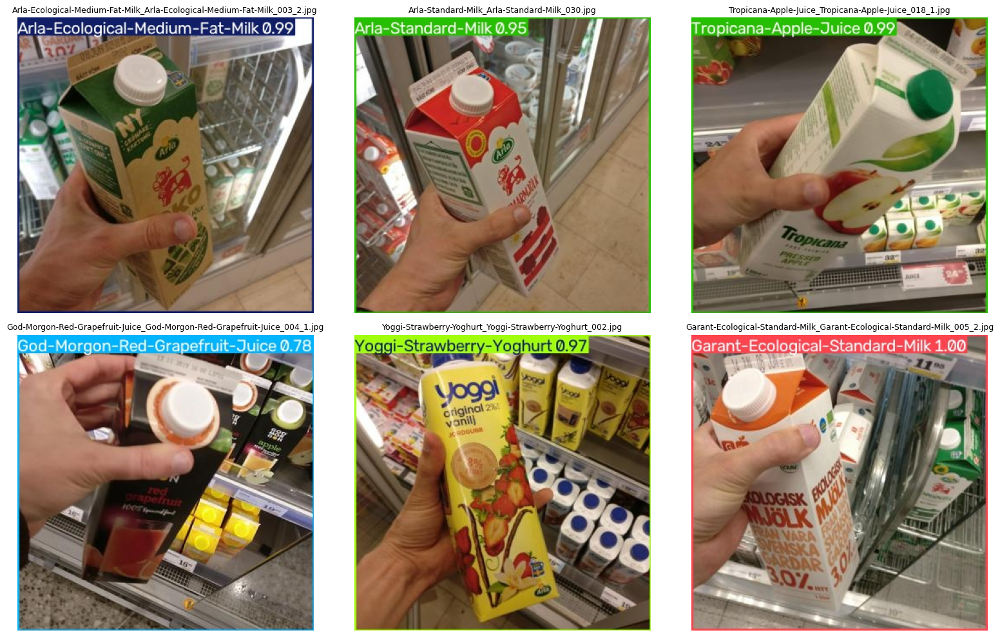

In [ ]:
import glob
import random
import shutil
import matplotlib.pyplot as plt
import cv2

# 1. Saari predicted images ko Google Drive par permanent save karein
src_dir = '/content/runs/detect/predict'
dst_dir = '/content/drive/MyDrive/Grocery_CCP_Project/yolo_runs/yolov8n_grocery/test_predictions'
shutil.copytree(src_dir, dst_dir, dirs_exist_ok=True)
print(f"Saari predicted images Drive par save ho gayi hain: {dst_dir}")

# 2. Screen par 6 random test results display karein
pred_images = glob.glob(f'{src_dir}/*.jpg')
samples = random.sample(pred_images, min(6, len(pred_images)))

plt.figure(figsize=(16, 10))
for i, img_path in enumerate(samples):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.axis('off')
    plt.title(img_path.split('/')[-1], fontsize=9)

plt.tight_layout()
plt.show()

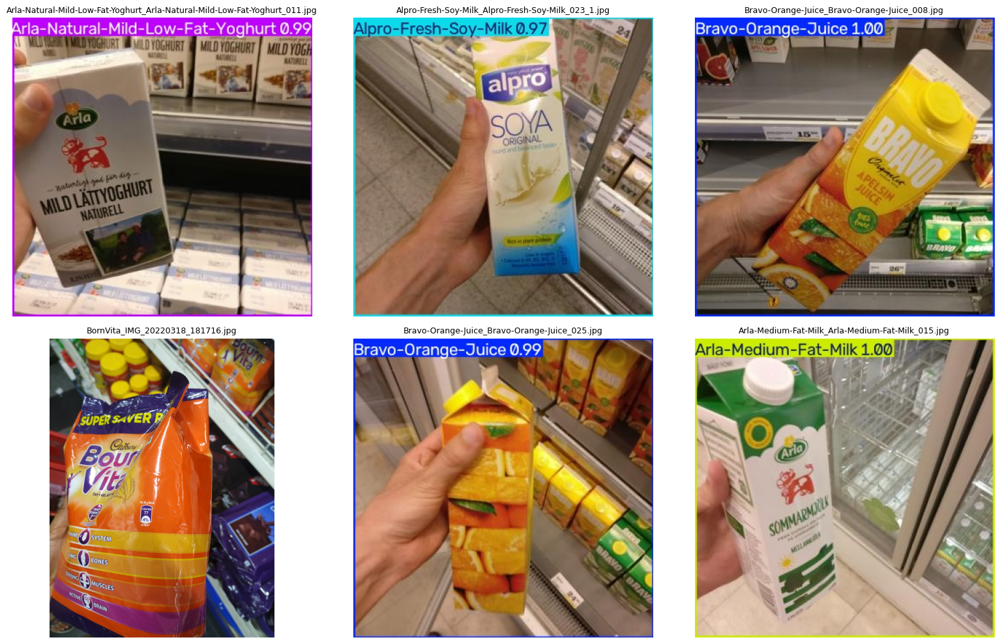

In [ ]:
# 2. Screen par 6 random test results display karein
pred_images = glob.glob(f'{src_dir}/*.jpg')
samples = random.sample(pred_images, min(6, len(pred_images)))

plt.figure(figsize=(16, 10))
for i, img_path in enumerate(samples):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.axis('off')
    plt.title(img_path.split('/')[-1], fontsize=9)

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')



Mounted at /content/drive


In [ ]:
print(list(model.names.values()))

['Alpro-Blueberry-Soyghurt', 'Alpro-Fresh-Soy-Milk', 'Alpro-Shelf-Soy-Milk', 'Alpro-Vanilla-Soyghurt', 'Arla-Ecological-Medium-Fat-Milk', 'Arla-Ecological-Sour-Cream', 'Arla-Lactose-Medium-Fat-Milk', 'Arla-Medium-Fat-Milk', 'Arla-Mild-Vanilla-Yoghurt', 'Arla-Natural-Mild-Low-Fat-Yoghurt', 'Arla-Natural-Yoghurt', 'Arla-Sour-Cream', 'Arla-Sour-Milk', 'Arla-Standard-Milk', 'Bakeparlor-Suji', 'Barley-Porridge', 'Black-Olives', 'BornVita', 'BornVita-5star-magic', 'Bravo-Apple-Juice', 'Bravo-Orange-Juice', 'Chicken-Soup-Stock', 'Dayfresh-Strawberry-Yougurt', 'Dorritos', 'Fizz-drink', 'Garant-Ecological-Medium-Fat-Milk', 'Garant-Ecological-Standard-Milk', 'God-Morgon-Apple-Juice', 'God-Morgon-Orange-Juice', 'God-Morgon-Orange-Red-Grapefruit-Juice', 'God-Morgon-Red-Grapefruit-Juice', 'IFFCO- IVY - soap', 'Imli-Sauce', 'Knorr-ChattPatta-Instant-Noodles', 'Lays', 'LemonMax-DishWashbar', 'MEC brightening - facewash', 'Marhaba-Quince', 'Mayo-Garlic-Sauce', "Mitchell's-Strawberry-Jam", 'Mountain-de

In [ ]:
from google.colab import files
from ultralytics import YOLO

# 1. PC se best.pt direct Colab mein upload karein
uploaded = files.upload()

# 2. ONNX mein export aur download karein
model = YOLO('best.pt')
onnx_path = model.export(format='onnx', imgsz=640, simplify=True)
files.download(onnx_path)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


Saving best.pt to best.pt
Ultralytics 8.4.215 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,149,231 parameters, 0 gradients, 8.7 GFLOPs

PyTorch: starting from 'best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 73, 8400) (6.2 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.18 environment at: /usr
Resolved 12 packages in 583ms
Prepared 4 packages in 1.26s
Installed 4 packages in 122ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.32.0
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 2.4s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>